In [1]:
!pip install -U FlagEmbedding

In [2]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

In [3]:
def fitPCA(X, n_components):
    X -= np.mean(X, axis=0)
    pca = PCA(n_components=n_components)
    X = pca.fit_transform(X)
    
    return X, pca.components_

def PPA(X, n_components, Tdim: int = 7):
    X, U = fitPCA(X, n_components)
    Z = []
    for x in X:
        for u in U[0:Tdim] :
            x = x - np.dot(u.T, x) * u
        Z.append(x)
    return np.array(Z)

def algo(X, n_components, Tdim: int = 7):
    dim = X.shape[1]
    X = PPA(X, dim, Tdim)
    X, _ = fitPCA(X, n_components)
    X = PPA(X, n_components, Tdim)
    
    return X

In [4]:
from FlagEmbedding import BGEM3FlagModel

model = BGEM3FlagModel('BAAI/bge-m3', use_fp16=True) 
def embedding(text) :
    return model.encode(text, max_length=1024)['dense_vecs']

/home/panyi/anaconda3/envs/llm/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 30 files: 100%|██████████| 30/30 [00:00<00:00, 380148.40it/s]


In [ ]:
def str2vec(item) :
    # remove brackets and split by " "
    item = item[1:-1].split(" ")
    # remove " " 
    item = [eval(_item) for _item in item if _item != ""]
    
    return item

def unify_vector(vector):
    return vector / sum(vector)
    
embedding_mapping = pd.read_csv("embedding_mapping.csv")
# embedding_mapping["vector"] = embedding_mapping["vector"].apply(lambda x: str2vec(x))
embedding_mapping["embed_vector"] = embedding_mapping["unique_categories"].apply(embedding)

In [ ]:
data = np.array([np.array(item) for item in embedding_mapping["embed_vector"].values])
embedding_mapping["vector"] = [list(item) for item in algo(data, 24)]

In [7]:
pca = PCA(n_components=2)
plot_data = pca.fit_transform(np.array(embedding_mapping["vector"].values.tolist()))
plot_data

array([[ 0.11491504, -0.02283916],
       [ 0.01950931,  0.07000757],
       [ 0.00755977,  0.06919556],
       ...,
       [-0.00018665, -0.06218689],
       [-0.06102317,  0.00215162],
       [ 0.06461099,  0.04402387]])

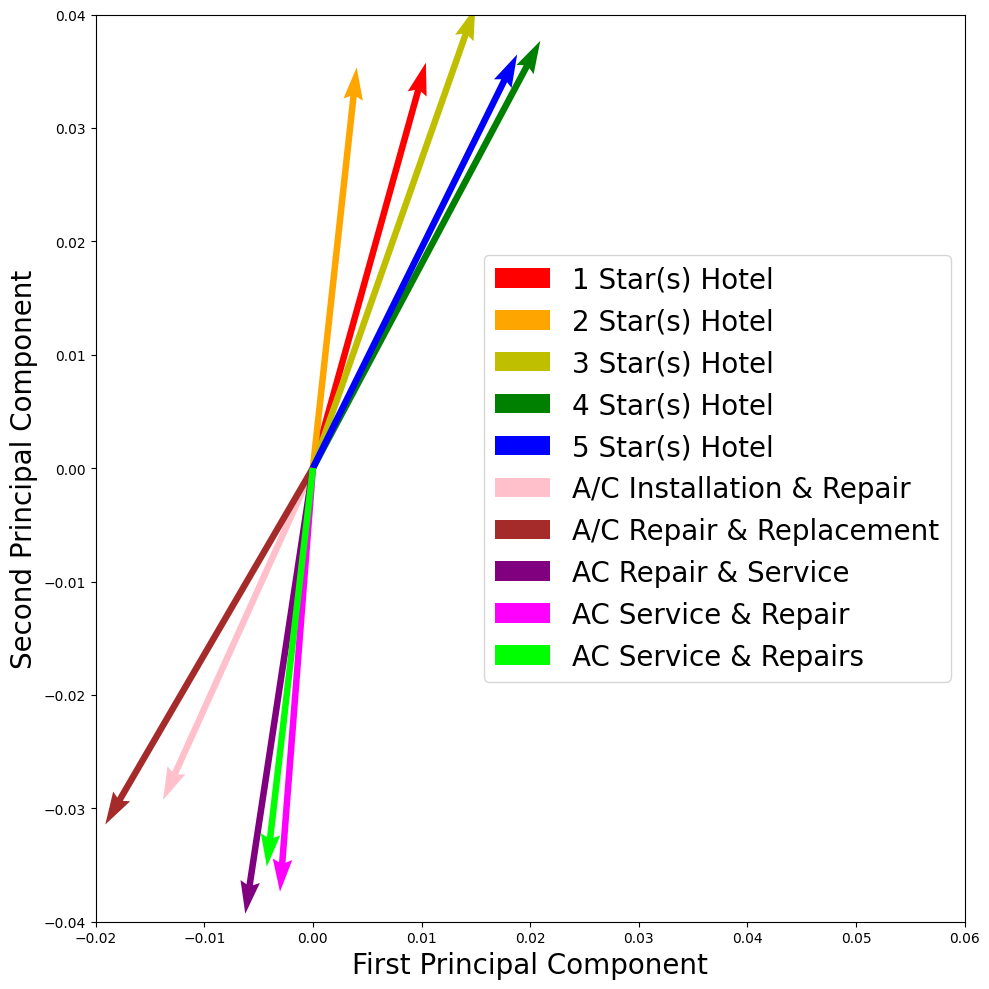

In [21]:
from matplotlib import pyplot as plt
plt.figure(figsize=(10,10))
plt.quiver(0, 0, plot_data[1, 0], plot_data[1, 1], scale = 0.15, color = "r", label = "1 Star(s) Hotel")
plt.quiver(0, 0, plot_data[2, 0], plot_data[2, 1], scale = 0.15, color = "orange", label = "2 Star(s) Hotel")
plt.quiver(0, 0, plot_data[5, 0], plot_data[5, 1], scale = 0.15, color = "y", label = "3 Star(s) Hotel")
plt.quiver(0, 0, plot_data[7, 0], plot_data[7, 1], scale = 0.15, color = "g", label = "4 Star(s) Hotel")
plt.quiver(0, 0, plot_data[8, 0], plot_data[8, 1], scale = 0.15, color = "b", label = "5 Star(s) Hotel")
# plt.quiver(0, 0, plot_data[13, 0], plot_data[13, 1], scale = 0.2, color = "purple", label = "A/C Installation")
plt.quiver(0, 0, plot_data[14, 0], plot_data[14, 1], scale = 0.45, color = "pink", label = "A/C Installation & Repair")
plt.quiver(0, 0, plot_data[16, 0], plot_data[16, 1], scale = 0.45, color = "brown", label = "A/C Repair & Replacement")
# plt.quiver(0, 0, plot_data[17, 0], plot_data[17, 1], scale = 0.2, color = "gray", label = "A/C System Replacement")
plt.quiver(0, 0, plot_data[32, 0], plot_data[32, 1], scale = 0.45, color = "purple", label = "AC Repair & Service")
plt.quiver(0, 0, plot_data[34, 0], plot_data[34, 1], scale = 0.45, color = "magenta", label = "AC Service & Repair")
plt.quiver(0, 0, plot_data[35, 0], plot_data[35, 1], scale = 0.45, color = "lime", label = "AC Service & Repairs")
plt.legend(loc = "right", fontsize = 20)
plt.xlim(-0.02, 0.06)
plt.ylim(-0.04, 0.04)
plt.xlabel("First Principal Component", fontsize = 20)
plt.ylabel("Second Principal Component", fontsize = 20)
plt.tight_layout()
plt.savefig("PCA_plot.pdf", dpi = 400)
plt.show()

In [9]:
# embedding_mapping.to_csv("embedding_mapping.csv", index=False)
embedding_mapping.to_csv("embedding_mapping_plot.csv", index=False)